In [17]:
import pickle
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

In [30]:
dataset = "yao_10x"
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")

In [12]:
#to load the pkl file:
with open(os.path.join(res_path, "yao_10x_v2_pca50.pkl"), 'rb') as f:
     pkl_file= pickle.load(f)

pkl_file.keys() #output: dict_keys(['clusters', 'clusterColors', 'clusterNames', 'pca50'])


dict_keys(['clusters', 'clusterColors', 'clusterNames', 'pca50'])

In [18]:
meta = pd.read_csv(os.path.join(res_path, "10x_metadata.csv"))

In [19]:
meta["donor_sex_label"].values[:20]

array(['M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M',
       'F', 'M', 'M', 'M', 'M', 'M', 'M'], dtype=object)

In [13]:
pkl_file['pca50'].shape

(1169213, 50)

In [14]:
pkl_file['clusters'][:10]

array([115, 363,  17,  14,  17,  17,  17,  14,  17,  17])

In [16]:
pkl_file['clusterNames'][pkl_file['clusters'][:10]]

array(['116_Pvalb', '364_DG', '18_Lamp5', '15_Lamp5', '18_Lamp5',
       '18_Lamp5', '18_Lamp5', '15_Lamp5', '18_Lamp5', '18_Lamp5'],
      dtype='<U23')

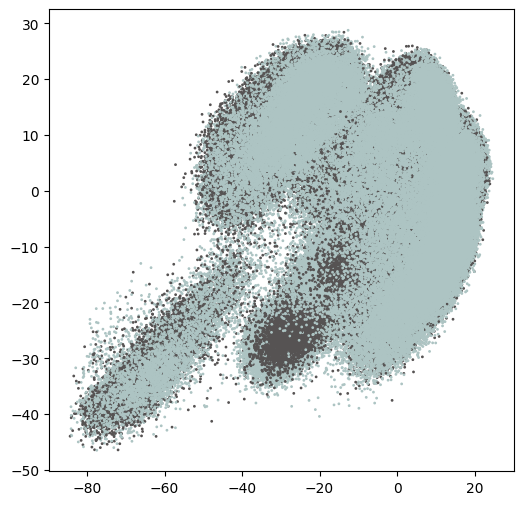

In [20]:
fig, ax = plt.subplots(figsize=(6,6))

#ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=pkl_file['clusterColors'][pkl_file['clusters']])
ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=meta["donor_sex_color"])

In [21]:
def load_dict(filename_):
    with open(filename_, 'rb') as f:
        ret_di = pickle.load(f)
    return ret_di

In [22]:
k = 15
n_epochs = 500
n_early_epochs = 250
perplexity = None
rescale_tsne = True
seed = 0

file_name = os.path.join(res_path,
                         f"tsne_bin_k_{k}_n_epochs_{n_epochs}_n_early_epochs_{n_early_epochs}_seed_{seed}_init_pca_rescale_{rescale_tsne}.pkl")

tsne_data = load_dict(file_name)
embd = tsne_data["embds"][-1]

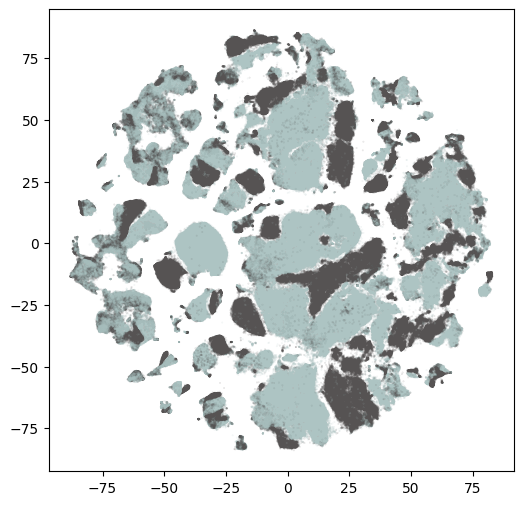

In [25]:
fig, ax = plt.subplots(figsize=(6,6))

#ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=pkl_file['clusterColors'][pkl_file['clusters']])
ax.scatter(*embd.T, s=0.1, c=meta["donor_sex_color"], alpha=0.2)

In [26]:
# only purple

In [32]:
full_d = load_dict(os.path.join(res_path, "yao.pkl"))

#cannot really find "Serpinf1", but on the paper according to fig 2D, it should be 21_ to 24_, and 41_ and 40_, so its already included in vip and Sncg
#but should i also included _Ntng1, according to fig 2D..... and lamp5_pax6 is labeled as "_Pax6, so i also added it in....
idx_purple = [i for i, cluster in enumerate(full_d["clusterNames"])
              if "_Lamp5" in cluster and "Lhx6" not in cluster or "_Vip" in cluster or "_Sncg" in cluster or "_Pax6" in cluster or "_Ntng1" in cluster]
cluster_purple = [cluster for i, cluster in enumerate(full_d["clusterNames"])
                  if "_Lamp5" in cluster and "Lhx6" not in cluster or "_Vip" in cluster or "_Sncg" in cluster or "_Pax6" in cluster or "_Ntng1" in cluster]


mask_purple = [idx in idx_purple for idx in full_d['clusters']]
idx_mask_purple = [i for i, idx in enumerate(full_d['clusters']) if idx in idx_purple ]

In [33]:
full_d.keys()

dict_keys(['counts', 'genes', 'clusters', 'clusterColors', 'clusterNames'])

In [42]:
mask_purple = np.array(mask_purple)

In [43]:
embd_purple = embd[mask_purple]

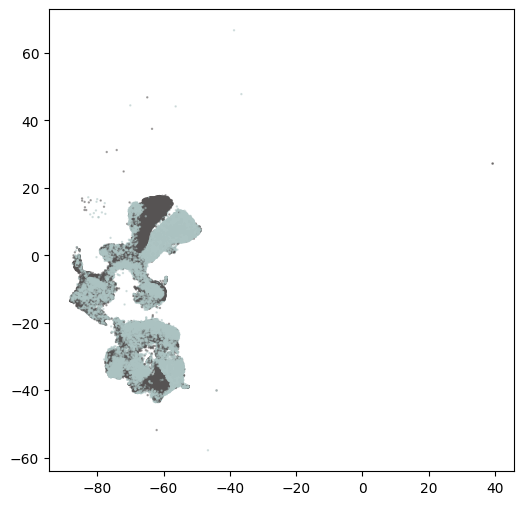

In [46]:
fig, ax = plt.subplots(figsize=(6,6))
#ax.scatter(*embd_purple.T, s=0.5, c=pkl_file['clusterColors'][pkl_file['clusters'][mask_purple]], alpha=0.5)
ax.scatter(*embd_purple.T, s=0.5, c=meta["donor_sex_color"][mask_purple], alpha=0.5)


In [107]:
seed = 0
np.random.seed(seed)
subsample_idx = np.random.choice(len(embd_purple), size=5000, replace=False)

subsample_purple_mask = np.array([True if i in subsample_idx else False for i in range(len(embd_purple))])

subsample_full_idx = np.arange(len(embd))[mask_purple][subsample_idx]
subsample_mask = np.array([True if i in subsample_full_idx else False for i in range(len(embd))])

In [118]:
full_mask = mask_purple * subsample_mask
mask_female = np.array(meta["donor_sex_label"][full_mask]) == "F"
mask_male = np.array(meta["donor_sex_label"][full_mask]) == "M"

In [119]:
mask_female.sum()

np.int64(1750)

In [120]:
mask_male.sum()

np.int64(3250)

In [115]:
np.array(meta[""][full_mask])[10:]

array(['#ADC4C3', '#565353', '#ADC4C3', ..., '#ADC4C3', '#ADC4C3',
       '#ADC4C3'], shape=(4990,), dtype=object)

Text(0.5, 0.98, 'tSNE of CGE-derived interneurons in Yao 10x dataset')

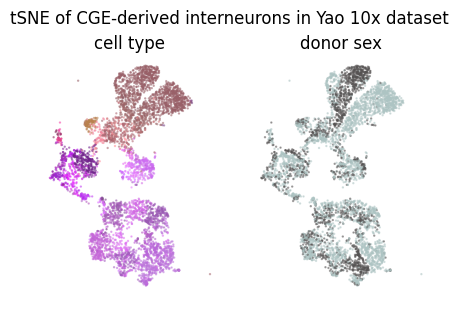

In [94]:
fig, ax = plt.subplots(1, 2, figsize=(5,3.5))

ax[0].scatter(*embd[full_mask].T, s=0.5, c=pkl_file['clusterColors'][pkl_file['clusters'][full_mask]], alpha=0.5)
ax[0].set_title("cell type")

("cell type")

ax[1].scatter(*embd[full_mask].T, s=0.5, c=np.array(meta["donor_sex_color"][full_mask]), alpha=0.5)
ax[1].set_title("donor sex")

for cax in ax:
    cax.axis('off')
    cax.set_ylim(None, 20)
    cax.set_aspect('equal')

fig.suptitle("joint tSNE of CGE-derived interneurons in Yao 10x dataset")

In [99]:
from openTSNE import TSNE

In [104]:
embedder = TSNE(verbose=True)
embd_full_pca = embedder.fit(pkl_file['pca50'][full_mask])

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.90 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.16 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=416.67 for 250 iterations...
Iteration   50, KL divergence 3.8230, 50 iterations in 7.2110 sec
Iteration  100, KL divergence 3.8801, 50 iterations in 6.6791 sec
Iteration  150, KL divergence 3.8839, 50 iterations in 6.4896 sec
Iteration  200, KL divergence 3.8834, 50 iterations in 6.5687 sec
Iteration  250, KL divergence 3.8832, 50 iterations in 6.6209 sec
   --> Time elapsed: 33.57 seconds
===> Running optimization with exaggeration=1.00, lr=5000.00 for 500 ite

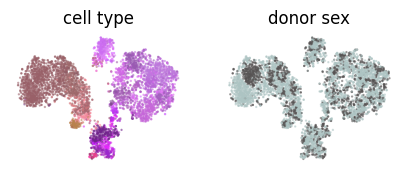

In [111]:
fig, ax = plt.subplots(1, 2, figsize=(5,3.5))

ax[0].scatter(*embd_full_pca.T, s=0.5, c=pkl_file['clusterColors'][pkl_file['clusters'][full_mask]], alpha=0.5)
ax[0].set_title("cell type")

ax[1].scatter(*embd_full_pca.T, s=0.5, c=np.array(meta["donor_sex_color"][full_mask]), alpha=0.5)
ax[1].set_title("donor sex")

for cax in ax:
    cax.axis('off')
    #cax.set_ylim(None, 20)
    cax.set_aspect('equal')


In [95]:
dataset = "yao_10x_purple"

In [96]:
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)

In [97]:
d = load_dict(os.path.join(res_path, "yao.pkl"))

In [123]:
pca50_purple = np.load(os.path.join(res_path, "pca50.npy"))

In [108]:
embedder = TSNE(verbose=True)
embd_purple_pca = embedder.fit(pca50_purple[subsample_purple_mask])

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.89 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.16 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=416.67 for 250 iterations...
Iteration   50, KL divergence 3.8219, 50 iterations in 7.3257 sec
Iteration  100, KL divergence 3.8798, 50 iterations in 6.6744 sec
Iteration  150, KL divergence 3.8839, 50 iterations in 6.5441 sec
Iteration  200, KL divergence 3.8836, 50 iterations in 6.6596 sec
Iteration  250, KL divergence 3.8835, 50 iterations in 6.6307 sec
   --> Time elapsed: 33.84 seconds
===> Running optimization with exaggeration=1.00, lr=5000.00 for 500 ite

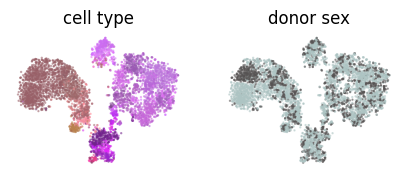

In [121]:
fig, ax = plt.subplots(1, 2, figsize=(5,3.5))

ax[0].scatter(*embd_purple_pca.T, s=0.5, c=pkl_file['clusterColors'][pkl_file['clusters'][full_mask]], alpha=0.5)
ax[0].set_title("cell type")

ax[1].scatter(*embd_purple_pca.T, s=0.5, c=np.array(meta["donor_sex_color"][full_mask]), alpha=0.5)
ax[1].set_title("donor sex")

for cax in ax:
    cax.axis('off')
    #cax.set_ylim(None, 20)
    cax.set_aspect('equal')


In [124]:
np.allclose(pca50_purple , pkl_file['pca50'][mask_purple])

True